# 02 — Preprocesamiento: filtros y normalización

**Objetivo:** entender qué le hacemos a la señal *antes* de extraer features.
Al terminar deberías poder explicar:
- qué es un filtro pasa bajo, pasa alto y pasa banda, y qué significan la
  **frecuencia de corte** y el **orden**;
- por qué filtramos "hacia adelante y hacia atrás" (fase cero);
- qué es normalizar la amplitud y por qué puede importar para el modelo.

**Importante:** en esta notebook solo *miramos y escuchamos* el efecto de cada
preprocesamiento. **No** medimos todavía si mejora la clasificación: eso se hace
en la notebook 10, con la validación ya definida. Si eligiéramos el filtro
mirando el AUC acá, estaríamos ajustando el preprocesamiento a los mismos
datos con los que después evaluamos (una forma de fuga de información).

In [6]:
import sys
from pathlib import Path

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, display
from scipy import signal

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.features import normalize_lung_id
from src.paths import AUDIO, DATA_DIR

SR = 4000          # frecuencia nativa de HLS-CMDS (ver notebook 01)
NYQUIST = SR / 2   # 2000 Hz: ningún corte puede superar este valor

hs = pd.read_csv(DATA_DIR / "HS.csv")
ls = pd.read_csv(DATA_DIR / "LS.csv")
ls["Lung Sound ID"] = ls["Lung Sound ID"].map(normalize_lung_id)


def cargar(subset, file_id):
    """Carga un .wav a la frecuencia nativa."""
    y, _ = librosa.load(AUDIO[subset] / f"{file_id}.wav", sr=SR)
    return y

## 1. ¿Qué es un filtro?

Un filtro deja pasar algunas frecuencias y atenúa otras.

| Filtro | Deja pasar | Equivalente clínico |
|---|---|---|
| **Pasa bajo** | lo que está *por debajo* del corte | la campana del estetoscopio |
| **Pasa alto** | lo que está *por encima* del corte | el diafragma |
| **Pasa banda** | lo que está *entre* dos cortes | combinación de ambos |

Usamos un filtro **Butterworth**, el más común: es "plano" en la zona que deja
pasar (no deforma esas frecuencias). Tiene dos parámetros:
- **Frecuencia de corte:** dónde empieza a atenuar. En el corte, la señal ya
  está atenuada a ~70 % de su amplitud (-3 dB).
- **Orden:** qué tan "abrupta" es la caída después del corte. Orden bajo =
  caída suave; orden alto = caída más de golpe.

La curva que describe un filtro se llama **respuesta en frecuencia**: para cada
frecuencia, qué fracción de la amplitud deja pasar.

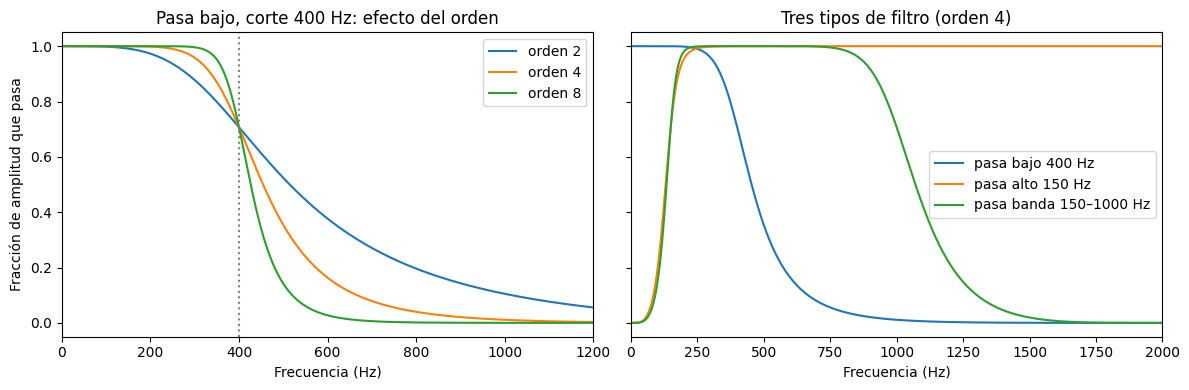

In [7]:
def disenar_filtro(tipo, corte, orden=4):
    """Filtro Butterworth. tipo: 'lowpass', 'highpass' o 'bandpass'.
    corte: un número en Hz, o (bajo, alto) para pasa banda."""
    return signal.butter(orden, corte, btype=tipo, fs=SR, output="sos")


fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for orden in [2, 4, 8]:
    w, h = signal.sosfreqz(disenar_filtro("lowpass", 400, orden), worN=4000, fs=SR)
    axes[0].plot(w, np.abs(h), label=f"orden {orden}")
axes[0].axvline(400, color="gray", ls=":")
axes[0].set(title="Pasa bajo, corte 400 Hz: efecto del orden", xlabel="Frecuencia (Hz)",
            ylabel="Fracción de amplitud que pasa", xlim=(0, 1200))
axes[0].legend()

for tipo, corte, nombre in [("lowpass", 400, "pasa bajo 400 Hz"),
                            ("highpass", 150, "pasa alto 150 Hz"),
                            ("bandpass", (150, 1000), "pasa banda 150–1000 Hz")]:
    w, h = signal.sosfreqz(disenar_filtro(tipo, corte), worN=4000, fs=SR)
    axes[1].plot(w, np.abs(h), label=nombre)
axes[1].set(title="Tres tipos de filtro (orden 4)", xlabel="Frecuencia (Hz)", xlim=(0, 2000))
axes[1].legend()
fig.tight_layout()

Ningún filtro real corta "a cuchillo": siempre hay una zona de transición. Un
orden más alto acerca el filtro al corte ideal, pero puede producir
oscilaciones ("ringing") alrededor de eventos bruscos, como un R1 o un
crepitante. Orden 4 es un compromiso habitual.

## 2. Filtrar sin correr la señal en el tiempo (fase cero)

Un filtro aplicado "hacia adelante" **retrasa** un poco la señal, y retrasa más
unas frecuencias que otras. En un sonido cardíaco eso desplazaría R1 y R2.

`sosfiltfilt` filtra hacia adelante y después hacia atrás: los retrasos se
cancelan (**fase cero**). Comparamos las dos formas sobre un sonido normal:

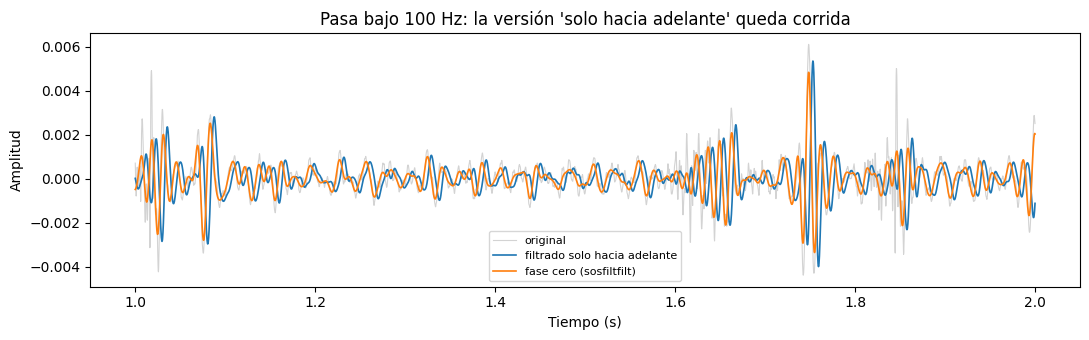

In [8]:
def filtrar(y, tipo, corte, orden=4):
    """Aplica el filtro con fase cero (sin desplazar la señal en el tiempo)."""
    return signal.sosfiltfilt(disenar_filtro(tipo, corte, orden), y)


y = cargar("HS", "F_N_RC")
t = np.arange(len(y)) / SR
solo_adelante = signal.sosfilt(disenar_filtro("lowpass", 100), y)
fase_cero = filtrar(y, "lowpass", 100)

fig, ax = plt.subplots(figsize=(11, 3.5))
ventana = (t > 1) & (t < 2)
ax.plot(t[ventana], y[ventana], color="lightgray", lw=0.8, label="original")
ax.plot(t[ventana], solo_adelante[ventana], lw=1.2, label="filtrado solo hacia adelante")
ax.plot(t[ventana], fase_cero[ventana], lw=1.2, label="fase cero (sosfiltfilt)")
ax.set(xlabel="Tiempo (s)", ylabel="Amplitud", title="Pasa bajo 100 Hz: la versión 'solo hacia adelante' queda corrida")
ax.legend(fontsize=8)
fig.tight_layout()

Usamos un corte de 100 Hz solo para que el efecto se vea bien. De acá en
adelante, **siempre fase cero**.

## 3. Pasa bajo sobre sonidos cardíacos

La notebook 01 mostró que el 95 % de la energía cardíaca está, en promedio,
por debajo de ~360 Hz. Probamos tres cortes sobre un soplo, que es justamente
el sonido que más riesgo tiene de perder información con un corte bajo.

original


pasa bajo 200 Hz


pasa bajo 400 Hz


pasa bajo 600 Hz


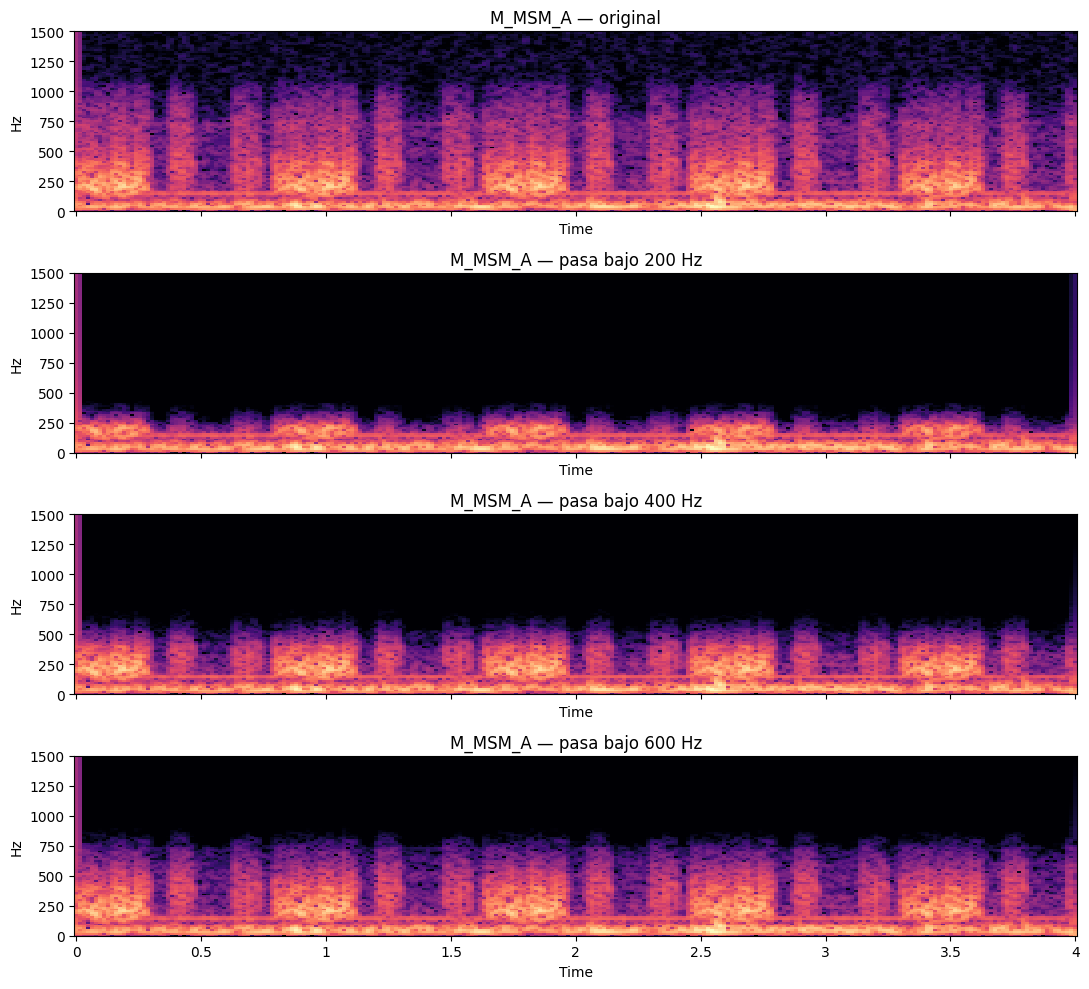

In [9]:
CORTES_HS = [200, 400, 600]
file_id = hs.loc[hs["Heart Sound Type"] == "Mid Systolic Murmur", "Heart Sound ID"].iloc[0]
y = cargar("HS", file_id)
N_FFT, HOP, SEG = 256, 64, 4

versiones = {"original": y, **{f"pasa bajo {c} Hz": filtrar(y, "lowpass", c) for c in CORTES_HS}}

fig, axes = plt.subplots(len(versiones), 1, figsize=(11, 10), sharex=True)
for ax, (nombre, yy) in zip(axes, versiones.items()):
    S = librosa.amplitude_to_db(np.abs(librosa.stft(yy[:SEG * SR], n_fft=N_FFT, hop_length=HOP)),
                                ref=np.max(np.abs(librosa.stft(y[:SEG * SR], n_fft=N_FFT, hop_length=HOP))))
    librosa.display.specshow(S, sr=SR, hop_length=HOP, x_axis="time", y_axis="hz", ax=ax, vmin=-80, vmax=0)
    ax.set(title=f"{file_id} — {nombre}", ylim=(0, 1500))
fig.tight_layout()

for nombre, yy in versiones.items():
    print(nombre)
    display(Audio(yy, rate=SR))

Todos los espectrogramas usan la misma referencia de dB (la del original), así
lo que el filtro borra se ve oscuro. Escuchá cómo cambia el soplo con cada
corte: con 200 Hz, ¿se sigue oyendo el "relleno" entre los ruidos?

## 4. Un artefacto: el tono fijo de ~146 Hz

En el espectrograma original de la sección 3 se ve una **línea horizontal
fina** cerca de 150 Hz que atraviesa toda la grabación, incluso en los
silencios entre latidos. Ningún sonido fisiológico produce un tono fijo y
continuo: lo más probable es que venga del maniquí o del equipo de grabación.

Tres preguntas:
1. ¿En qué frecuencia exacta está y en cuántas grabaciones aparece?
2. ¿Aparece más en una clase que en la otra? Si es así, sería una pista sin
   sentido clínico que el modelo podría aprovechar (como el volumen, sección 6).
3. ¿Se puede sacar sin dañar el resto del sonido?

Para medir el tono comparamos, en el espectro de cada grabación, la potencia
en la frecuencia del tono con la de las frecuencias vecinas. Si el tono no
existe, la diferencia es ~0 dB; si existe, es positiva.

In [10]:
def espectro_db(y, resolucion_hz=1):
    """Espectro de potencia (dB) con la resolución pedida en Hz."""
    freqs, p = signal.welch(y, fs=SR, nperseg=int(SR / resolucion_hz))
    return freqs, 10 * np.log10(p + 1e-20)


def fuerza_tono(y, f0):
    """Cuántos dB sobresale el espectro en f0 (±2 Hz) respecto de sus vecinas (±5 a ±25 Hz)."""
    freqs, db = espectro_db(y)
    pico = db[(freqs >= f0 - 2) & (freqs <= f0 + 2)].max()
    vecinas = ((freqs >= f0 - 25) & (freqs < f0 - 5)) | ((freqs > f0 + 5) & (freqs <= f0 + 25))
    return pico - np.median(db[vecinas])


# Frecuencia exacta: el máximo del espectro entre 130 y 160 Hz, en cada grabación
filas = []
for subset, meta, col_tipo, col_id in [("HS", hs, "Heart Sound Type", "Heart Sound ID"),
                                       ("LS", ls, "Lung Sound Type", "Lung Sound ID")]:
    for _, f in meta.iterrows():
        freqs, db = espectro_db(cargar(subset, f[col_id]))
        banda = (freqs >= 130) & (freqs <= 160)
        filas.append({"subconjunto": subset, "file_id": f[col_id],
                      "clase": "Normal" if f[col_tipo] == "Normal" else "Patológico",
                      "f_pico": freqs[banda][np.argmax(db[banda])]})
tono = pd.DataFrame(filas)
F_TONO = float(tono["f_pico"].median())
print(f"Frecuencia del tono (mediana de todas las grabaciones): {F_TONO:.0f} Hz")

tono["fuerza_dB"] = [fuerza_tono(cargar(r.subconjunto, r.file_id), F_TONO) for r in tono.itertuples()]
tono["tiene_tono"] = tono["fuerza_dB"] > 6     # umbral: el pico sobresale más de 6 dB
print(tono.groupby(["subconjunto", "clase"]).agg(
    grabaciones=("tiene_tono", "size"), con_tono=("tiene_tono", "sum"),
    fuerza_mediana_dB=("fuerza_dB", "median")).round(1))

Frecuencia del tono (mediana de todas las grabaciones): 146 Hz
                        grabaciones  con_tono  fuerza_mediana_dB
subconjunto clase                                               
HS          Normal                9         9               14.4
            Patológico           41        28                8.3
LS          Normal               12         5                5.0
            Patológico           38        35               15.4


¿Diferencia entre clases? Igual que con el volumen, usamos el AUC: la
probabilidad de que una grabación patológica tenga el tono más fuerte que una
normal elegida al azar. 0,5 = el tono no distingue las clases.

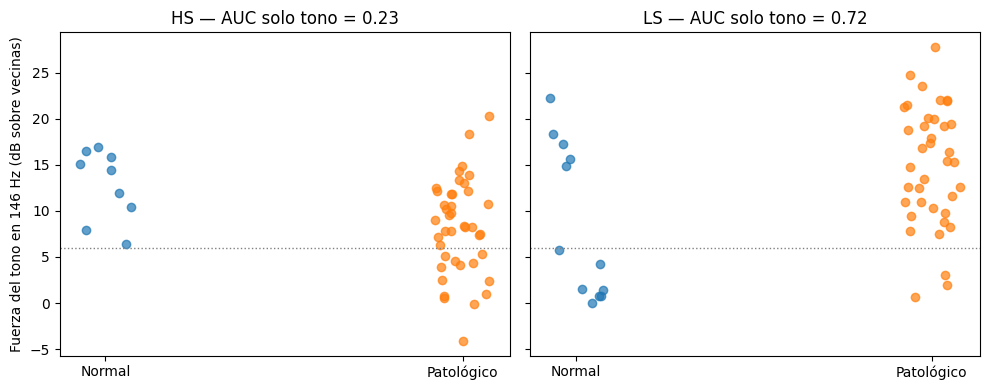

In [11]:
from sklearn.metrics import roc_auc_score

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, subset in zip(axes, ["HS", "LS"]):
    d = tono[tono.subconjunto == subset]
    auc = roc_auc_score(d.clase == "Patológico", d.fuerza_dB)
    for i, clase in enumerate(["Normal", "Patológico"]):
        v = d.loc[d.clase == clase, "fuerza_dB"]
        ax.scatter(np.full(len(v), i) + np.random.uniform(-0.08, 0.08, len(v)), v, alpha=0.7)
    ax.axhline(6, color="gray", ls=":", lw=1)
    ax.set(xticks=[0, 1], xticklabels=["Normal", "Patológico"], title=f"{subset} — AUC solo tono = {auc:.2f}")
axes[0].set_ylabel(f"Fuerza del tono en {F_TONO:.0f} Hz (dB sobre vecinas)")
fig.tight_layout()

### El filtro rechaza banda (*notch*)

Un **notch** elimina una franja muy angosta alrededor de una frecuencia y deja
todo lo demás intacto. Tiene dos parámetros:
- **f0:** la frecuencia a eliminar (la del tono).
- **Q (factor de calidad):** qué tan angosta es la franja. Q = f0 / ancho de la
  franja. Con f0 = 146 Hz y Q = 30, la franja mide ~5 Hz. Q más alto = más
  angosta (se pierde menos sonido real, pero si el tono "se corre" un poco ya
  no lo atrapa).

Como con el Butterworth, lo aplicamos ida y vuelta (fase cero).

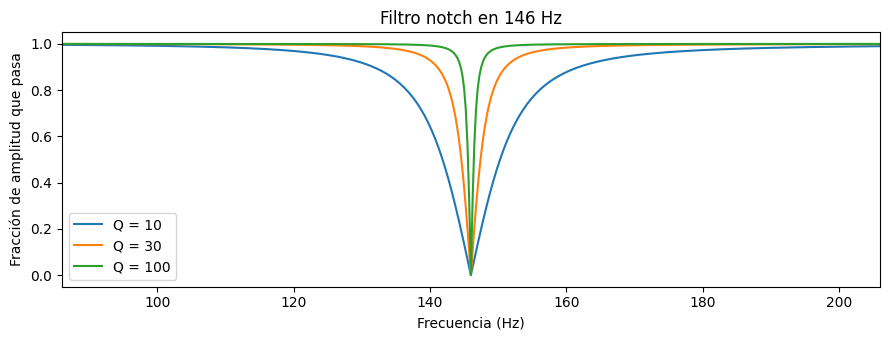

In [12]:
def quitar_tono(y, f0, q=30):
    """Filtro notch en f0 Hz, con fase cero."""
    b, a = signal.iirnotch(f0, q, fs=SR)
    return signal.filtfilt(b, a, y)


fig, ax = plt.subplots(figsize=(9, 3.5))
for q in [10, 30, 100]:
    b, a = signal.iirnotch(F_TONO, q, fs=SR)
    w, h = signal.freqz(b, a, worN=8000, fs=SR)
    ax.plot(w, np.abs(h), label=f"Q = {q}")
ax.set(xlim=(F_TONO - 60, F_TONO + 60), xlabel="Frecuencia (Hz)",
       ylabel="Fracción de amplitud que pasa", title=f"Filtro notch en {F_TONO:.0f} Hz")
ax.legend()
fig.tight_layout()

Lo aplicamos al soplo de la sección 3 y comparamos el espectro alrededor del
tono, el espectrograma y el sonido:

original


con notch


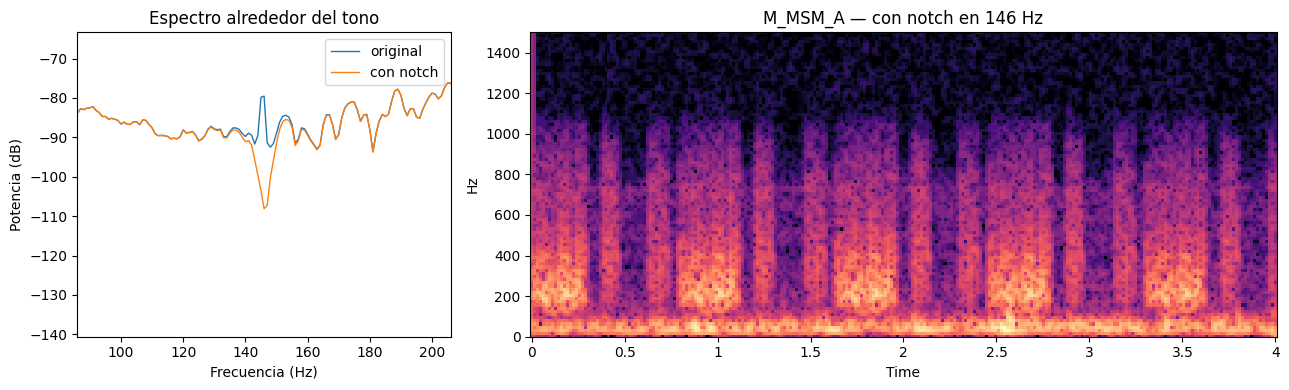

In [13]:
y = cargar("HS", file_id)
y_notch = quitar_tono(y, F_TONO)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 2]})
for senal, nombre in [(y, "original"), (y_notch, "con notch")]:
    freqs, db = espectro_db(senal)
    axes[0].plot(freqs, db, lw=1, label=nombre)
axes[0].set(xlim=(F_TONO - 60, F_TONO + 60), xlabel="Frecuencia (Hz)", ylabel="Potencia (dB)",
            title="Espectro alrededor del tono")
axes[0].legend()
S = librosa.amplitude_to_db(np.abs(librosa.stft(y_notch[:SEG * SR], n_fft=N_FFT, hop_length=HOP)),
                            ref=np.max(np.abs(librosa.stft(y[:SEG * SR], n_fft=N_FFT, hop_length=HOP))))
librosa.display.specshow(S, sr=SR, hop_length=HOP, x_axis="time", y_axis="hz", ax=axes[1], vmin=-80, vmax=0)
axes[1].set(title=f"{file_id} — con notch en {F_TONO:.0f} Hz", ylim=(0, 1500))
fig.tight_layout()

for nombre, senal in [("original", y), ("con notch", y_notch)]:
    print(nombre)
    display(Audio(senal, rate=SR))

Comparalo con el espectrograma original de la sección 3: la línea horizontal
debería haber desaparecido y el resto quedar igual. Por último, verificamos
que el notch saque el tono en **todas** las grabaciones:

In [14]:
tono["fuerza_dB_con_notch"] = [fuerza_tono(quitar_tono(cargar(r.subconjunto, r.file_id), F_TONO), F_TONO)
                               for r in tono.itertuples()]
print(tono.groupby("subconjunto")[["fuerza_dB", "fuerza_dB_con_notch"]].median().round(1))

             fuerza_dB  fuerza_dB_con_notch
subconjunto                                
HS                 9.3                 -9.5
LS                14.8                 -5.8


## 5. ¿Dónde se superponen el corazón y el pulmón?

Un filtro solo puede separar dos sonidos si ocupan **frecuencias distintas**.
Para ver cuánto se superponen usamos el subconjunto Mix: para cada mezcla
`M####` existen también sus dos componentes por separado, `H####` (cardíaco) y
`L####` (pulmonar).

Comparamos el **espectro promedio** (cuánta energía hay en cada frecuencia, en
promedio sobre toda la grabación) de las 145 componentes cardíacas y las 145
pulmonares, y le superponemos dos filtros candidatos.

*Nota:* la mezcla **no** es la suma muestra a muestra de sus componentes: se
grabó por separado en el maniquí y no está alineada en el tiempo con ellas.
Por eso no se puede "restar" un sonido del otro ni comparar formas de onda;
sí se pueden comparar espectros, que no dependen de cuándo ocurre cada cosa.

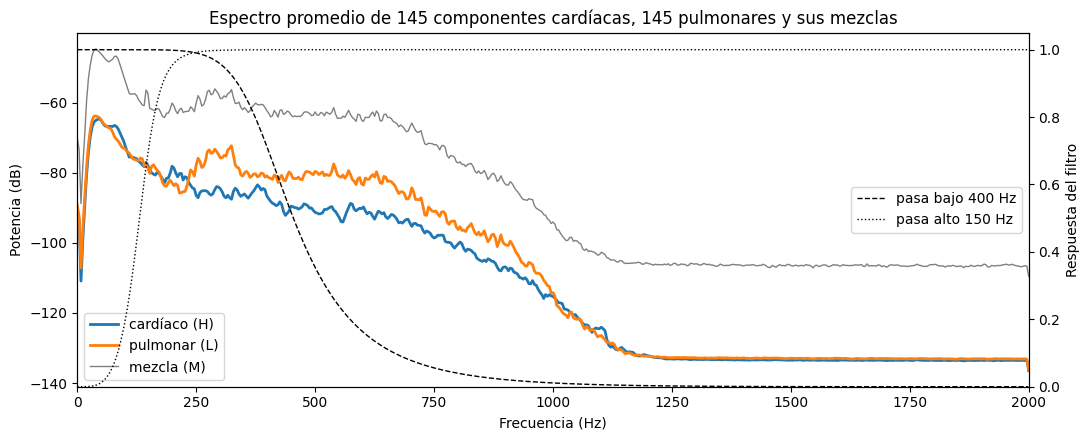

In [15]:
mix = pd.read_csv(DATA_DIR / "Mix.csv")


def espectro_promedio(ids):
    """Espectro de potencia promedio (en dB) de un conjunto de grabaciones de Mix."""
    potencias = []
    for i in ids:
        freqs, p = signal.welch(cargar("Mix", i), fs=SR, nperseg=1024)
        potencias.append(p)
    return freqs, 10 * np.log10(np.mean(potencias, axis=0))


freqs, esp_h = espectro_promedio(mix["Heart Sound ID"])
_, esp_l = espectro_promedio(mix["Lung Sound ID"])
_, esp_m = espectro_promedio(mix["Mixed Sound ID"])

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(freqs, esp_h, lw=2, label="cardíaco (H)")
ax.plot(freqs, esp_l, lw=2, label="pulmonar (L)")
ax.plot(freqs, esp_m, lw=1, color="gray", label="mezcla (M)")
ax.set(xlabel="Frecuencia (Hz)", ylabel="Potencia (dB)", xlim=(0, 2000),
       title="Espectro promedio de 145 componentes cardíacas, 145 pulmonares y sus mezclas")
ax2 = ax.twinx()
for tipo, corte, nombre, estilo in [("lowpass", 400, "pasa bajo 400 Hz", "--"),
                                    ("highpass", 150, "pasa alto 150 Hz", ":")]:
    w, h = signal.sosfreqz(disenar_filtro(tipo, corte), worN=2000, fs=SR)
    ax2.plot(w, np.abs(h), "k" + estilo, lw=1, label=nombre)
ax2.set(ylabel="Respuesta del filtro", ylim=(0, 1.05))
ax.legend(loc="lower left")
ax2.legend(loc="center right")
fig.tight_layout()

Para leer este gráfico:
- Donde las curvas cardíaca y pulmonar están **separadas** (una muy por encima
  de la otra), un filtro puede quedarse con una y atenuar la otra.
- Donde están **juntas**, ningún filtro puede separarlas: atenuar el pulmón
  ahí también atenúa el corazón.

Mirá con atención tres cosas:
1. ¿En qué rango se superponen? ¿Es solo la banda baja, como anticipa la
   sección 2.5 de la tesis, o más que eso?
2. ¿Qué pasa con las dos curvas por encima de ~1100 Hz? ¿Es un sonido del
   cuerpo o algo del equipo de grabación?
3. ¿Cuántos dB por encima de sus componentes está la mezcla? Relacionalo con
   la sección 6 (normalización).

Si un filtro ayuda o no a clasificar las mezclas lo medimos en la notebook 11.

## 6. Normalizar la amplitud

Cada grabación puede tener distinto "volumen" por razones que no son clínicas:
la presión del estetoscopio, la ganancia del equipo, la distancia al parlante
del maniquí. Si el volumen difiere sistemáticamente entre normales y
patológicos, el modelo puede aprender **el volumen** en lugar del sonido.

Dos formas de normalizar:
- **Por pico:** se divide la señal por su valor absoluto máximo. El punto más
  fuerte queda en 1. Simple, pero depende de un solo instante.
- **Por RMS:** se divide por la energía promedio (RMS = raíz del promedio de
  los cuadrados). Todas las grabaciones quedan con la misma energía media.

Primero miramos si el volumen difiere entre clases:

                           RMS    pico
subconjunto clase                     
HS          Normal      0.0042  0.0435
            Patológico  0.0033  0.0311
LS          Normal      0.0056  0.0341
            Patológico  0.0025  0.0233


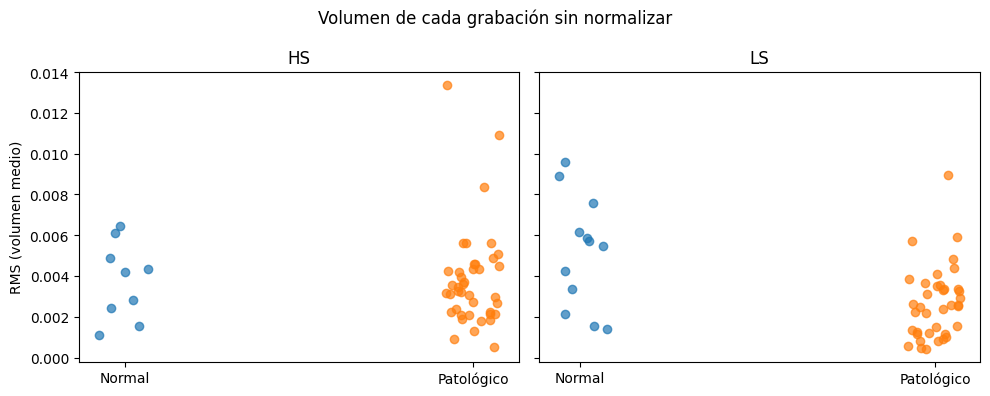

In [25]:
def rms(y):
    return np.sqrt(np.mean(y ** 2))


filas = []
for subset, meta, col_tipo, col_id in [("HS", hs, "Heart Sound Type", "Heart Sound ID"),
                                       ("LS", ls, "Lung Sound Type", "Lung Sound ID")]:
    for _, f in meta.iterrows():
        y = cargar(subset, f[col_id])
        filas.append({"subconjunto": subset,
                      "clase": "Normal" if f[col_tipo] == "Normal" else "Patológico",
                      "RMS": rms(y), "pico": np.max(np.abs(y))})
vol = pd.DataFrame(filas)
print(vol.groupby(["subconjunto", "clase"])[["RMS", "pico"]].median().round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, subset in zip(axes, ["HS", "LS"]):
    d = vol[vol.subconjunto == subset]
    for i, clase in enumerate(["Normal", "Patológico"]):
        v = d.loc[d.clase == clase, "RMS"]
        ax.scatter(np.full(len(v), i) + np.random.uniform(-0.08, 0.08, len(v)), v, alpha=0.7)
    ax.set(xticks=[0, 1], xticklabels=["Normal", "Patológico"], title=subset)
axes[0].set_ylabel("RMS (volumen medio)")
fig.suptitle("Volumen de cada grabación sin normalizar")
fig.tight_layout()

Si los puntos de una clase están sistemáticamente más arriba que los de la
otra, el volumen es una "pista" que el modelo puede usar, y no tiene sentido
clínico.

¿Cuánto podría acertar un "clasificador" que solo mire el volumen? Usamos el
AUC (lo vemos a fondo en la notebook 05): la probabilidad de que, tomando una
grabación patológica y una normal al azar, la patológica tenga **menos**
volumen. 0,5 = el volumen no dice nada; 1 = el volumen separa perfecto.

In [26]:
for subset in ["HS", "LS"]:
    d = vol[vol.subconjunto == subset]
    auc = roc_auc_score(d.clase == "Patológico", -d.RMS)
    print(f"{subset}: AUC usando solo el volumen = {auc:.2f}")

HS: AUC usando solo el volumen = 0.54
LS: AUC usando solo el volumen = 0.78


En pulmonares, **el volumen solo ya da un AUC alto**. Eso no significa que el
modelo de la tesis use solo el volumen, pero sí que es una pista disponible y
sin sentido clínico: probablemente refleja cómo se grabaron los normales en
el maniquí, no una propiedad del pulmón sano. Normalizar la amplitud elimina
esa pista. Si el desempeño pulmonar cae mucho al normalizar, parte del
resultado venía del volumen. Lo medimos en la notebook 10.

En la notebook 03 vamos a ver que varias features (`rms_*`, `mfcc_1_*`) miden
casi exactamente esto.

In [28]:
def normalizar(y, metodo):
    """'pico': máximo absoluto = 1.  'rms': energía media = 1."""
    if metodo == "pico":
        return y / np.max(np.abs(y))
    if metodo == "rms":
        return y / rms(y)
    return y


y = cargar("HS", "F_N_RC")
for metodo in [None, "pico", "rms"]:
    yn = normalizar(y, metodo)
    print(f"{str(metodo):>5}: pico = {np.max(np.abs(yn)):.3f}   RMS = {rms(yn):.3f}")

 None: pico = 0.015   RMS = 0.001
 pico: pico = 1.000   RMS = 0.074
  rms: pico = 13.430   RMS = 1.000


## 7. La función de preprocesamiento

Juntamos todo en una sola función, que vamos a usar en las próximas notebooks.
El orden importa: **primero filtrar, después normalizar** (si se normaliza
antes, el filtro cambia la energía y la normalización se pierde).

In [29]:
def preprocesar(y, filtro=None, corte=None, orden=4, normalizacion=None, notch=None):
    """notch: None o la frecuencia del tono a eliminar (Hz).
    filtro: None, 'lowpass', 'highpass' o 'bandpass'.
    normalizacion: None, 'pico' o 'rms'."""
    if notch is not None:
        y = quitar_tono(y, notch)
    if filtro is not None:
        y = filtrar(y, filtro, corte, orden)
    return normalizar(y, normalizacion)

## 8. Tu turno

Cambiá los parámetros, escuchá y mirá el espectrograma. Ideas:
- un sonido pulmonar con pasa alto 150 Hz (¿se va algo que te importe?);
- un S3 o S4 con pasa bajo 200 Hz (son de muy baja frecuencia);
- un orden muy alto (8) sobre crepitantes: ¿aparece "ringing"?

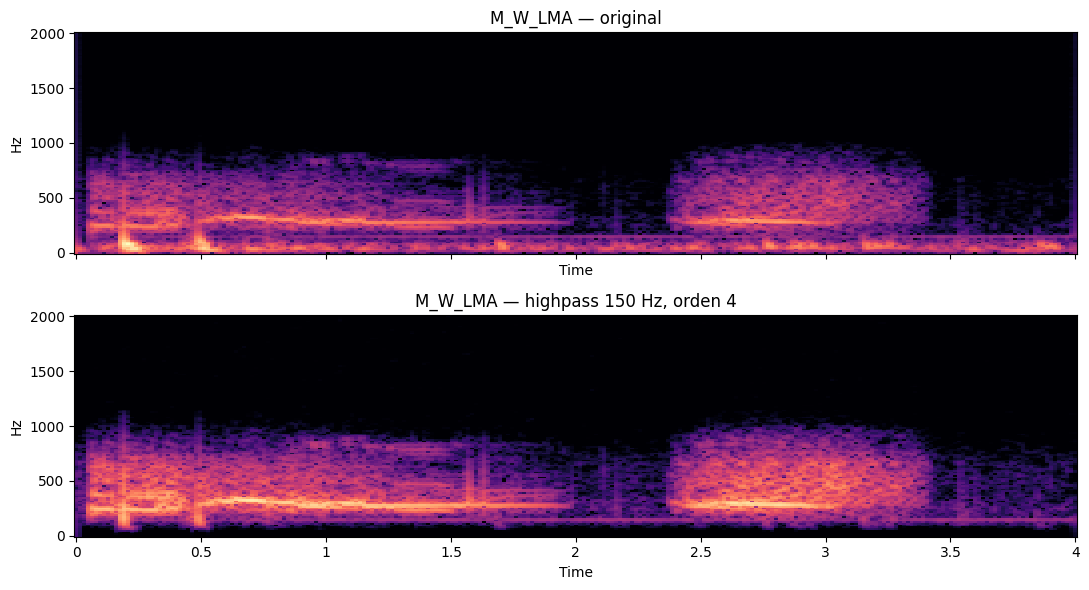

In [30]:
SUBSET, FILE_ID = "LS", "M_W_LMA"
FILTRO, CORTE, ORDEN = "highpass", 150, 4

y = cargar(SUBSET, FILE_ID)
yp = preprocesar(y, FILTRO, CORTE, ORDEN, normalizacion="pico")
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ref = np.max(np.abs(librosa.stft(y[:SEG * SR], n_fft=N_FFT, hop_length=HOP)))
for ax, (nombre, yy) in zip(axes, [("original", y), (f"{FILTRO} {CORTE} Hz, orden {ORDEN}", yp * np.max(np.abs(y)))]):
    S = librosa.amplitude_to_db(np.abs(librosa.stft(yy[:SEG * SR], n_fft=N_FFT, hop_length=HOP)), ref=ref)
    librosa.display.specshow(S, sr=SR, hop_length=HOP, x_axis="time", y_axis="hz", ax=ax, vmin=-80, vmax=0)
    ax.set(title=f"{FILE_ID} — {nombre}")
    display(Audio(yy, rate=SR))
fig.tight_layout()

In [24]:
y = cargar("HS", "M_MSM_A")
bandas = {
    "solo el tono (140–152 Hz)": filtrar(y, "bandpass", (140, 152)),
    "graves (< 80 Hz)":          filtrar(y, "lowpass", 80),
    "medios (80–400 Hz)":        filtrar(y, "bandpass", (80, 400)),
    "agudos (> 1500 Hz)":         filtrar(y, "highpass", 1500),
}
for nombre, b in bandas.items():
    print(nombre)
    display(Audio(b, rate=SR))


solo el tono (140–152 Hz)


graves (< 80 Hz)


medios (80–400 Hz)


agudos (> 1500 Hz)


## Preguntas de control

1. ¿Qué hace un filtro pasa bajo de 400 Hz? ¿Qué pasa exactamente en 400 Hz?
2. ¿Qué cambia al subir el orden del filtro? ¿Qué riesgo tiene un orden muy alto?
3. ¿Por qué usamos `sosfiltfilt` (fase cero) y no un filtrado común? Pensalo en
   términos de R1 y R2.
4. ¿Por qué decimos que el tono de ~146 Hz es un artefacto y no un sonido del
   cuerpo? ¿Aparece por igual en normales y patológicos? ¿Qué hace un filtro
   notch y qué significa el parámetro Q?
5. Según el gráfico de espectros, ¿en qué rango se superponen el corazón y el
   pulmón? ¿Qué implica eso para lo que puede lograr un filtro?
6. ¿Por qué es un problema que normales y patológicos tengan distinto volumen?
   ¿Qué diferencia hay entre normalizar por pico y por RMS? ¿Qué te dice el
   AUC "solo volumen" de los pulmonares sobre los resultados de la tesis?
7. ¿Por qué no elegimos acá el mejor filtro según el AUC del modelo?

1. ¿Qué hace un pasa bajo de 400 Hz? ¿Qué pasa exactamente en 400 Hz?
Deja pasar casi intactas las frecuencias por debajo de 400 Hz y atenúa cada vez más las que están por encima. En 400 Hz justo no corta: la señal pasa con el ~70 % de su amplitud (-3 dB). Ese es el punto que, por convención, marca dónde empieza la atenuación. Con sosfiltfilt, como se aplica dos veces, queda el 50 %.

2. ¿Qué cambia al subir el orden? ¿Qué riesgo tiene un orden muy alto?
El orden define qué tan empinada es la caída después del corte: a mayor orden, más se acerca a un corte "a cuchillo". El riesgo es el ringing: un filtro muy abrupto en frecuencia produce oscilaciones en el tiempo alrededor de eventos bruscos (R1, crepitantes), y los deforma. Orden 4 es el compromiso habitual.

3. ¿Por qué sosfiltfilt (fase cero)?
Un filtro de una sola pasada retrasa la señal, y la retrasa distinto según la frecuencia, así que correría R1 y R2 de su lugar y deformaría su forma. Aplicarlo ida y vuelta cancela el retraso, como un promedio móvil centrado en vez de uno que solo mira hacia atrás. Se puede porque tenemos la grabación completa; en tiempo real no se podría.

4. ¿Por qué el tono de 146 Hz es un artefacto? ¿Aparece igual en ambas clases? ¿Qué es un notch y qué es Q?

Es un tono fijo y continuo que está también en los silencios entre latidos, y ningún sonido del cuerpo hace eso.
No aparece igual: en cardíacos lo tienen más fuerte los normales (AUC 0,23, que dado vuelta es 0,77) y en pulmonares los patológicos (0,72). Es una pista sin sentido clínico que el modelo puede aprovechar.
Un notch elimina una franja muy angosta alrededor de una frecuencia y deja el resto intacto. Q define qué tan angosta: Q = f0 / ancho. Con Q = 30 en 146 Hz, la franja mide ~5 Hz.
5. ¿En qué rango se superponen corazón y pulmón? ¿Qué implica para un filtro?

Se superponen en casi todo el rango, no solo debajo de 200 Hz como dice tu sección 2.5. Las dos curvas tienen forma muy parecida; el pulmón está apenas 5–10 dB por encima entre ~200 y 1000 Hz.
Por eso ningún filtro de frecuencia puede separarlos bien: sacar uno implica sacar parte del otro.
Por encima de ~1100 Hz no hay nada en ninguno de los dos: es un límite del equipo, no del cuerpo.
La mezcla está ~20 dB por encima de sus componentes: se grabó con otra ganancia. Por eso normalizar es clave para las mezclas.
6. ¿Por qué es un problema la diferencia de volumen? ¿Pico vs. RMS? ¿Qué dice el AUC "solo volumen"?

Si una clase está grabada más fuerte, el modelo puede "acertar" por el volumen, que no tiene sentido clínico: refleja cómo se grabó, no el pulmón o el corazón.
Pico: divide por el valor máximo, así que depende de un solo instante (un golpe fuerte lo cambia todo). RMS: divide por la energía promedio, que es más estable.
En pulmonares, el volumen solo da AUC 0,78: parte del buen resultado pulmonar de la tesis podría venir de ahí. Hay que medirlo normalizando (notebook 10).
7. ¿Por qué no elegimos el filtro según el AUC del modelo acá?
Porque sería ajustar el preprocesamiento a los mismos datos con los que después evaluamos: una forma de fuga de información, igual que elegir hiperparámetros con los datos de prueba. Además, si probás muchos filtros, alguno gana por suerte. Por eso se definen pocos candidatos antes, con argumentos clínicos y de la señal, y se comparan todos con la misma validación.